# Final Test Evaluation - ECG Arrhythmia Classification

## Overview

This notebook performs the final evaluation of the selected deep learning model on the untouched test dataset.

During the experimentation phase, three deep learning architectures were evaluated:

- 1D CNN
- LSTM
- GRU

Each architecture was tested using both standard CrossEntropyLoss and class-weighted CrossEntropyLoss.

Based on validation performance, the LSTM Plain model was selected for final evaluation because it achieved the highest validation Macro-F1 score of approximately 94.43%.

The selected model is evaluated on the original Kaggle test dataset to assess its performance on previously unseen samples.

**Important:** The test dataset is used only for final evaluation and is not used for model training or hyperparameter tuning.


## 1. Evaluation Objectives

The main objectives of this notebook are:

1. Load the untouched test dataset.
2. Load the previously trained LSTM Plain checkpoint.
3. Generate predictions using the trained model.
4. Evaluate classification performance using multiple metrics.
5. Analyze class-wise performance through a classification report.
6. Visualize the confusion matrix to identify misclassification patterns.
7. Save the final evaluation results for project documentation.

The primary evaluation metric is Macro-F1 because the dataset contains a significant class imbalance.

In [23]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from torch.utils.data import DataLoader,Dataset
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

In [4]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)

Using device: cuda


## 2. Test Dataset Preparation

The project uses the ECG Heartbeat Categorization Dataset, derived from the MIT-BIH Arrhythmia Database.

Each sample contains:

- 187 numerical values representing an ECG heartbeat signal.
- One target label representing its corresponding heartbeat category.

The dataset contains five classification categories:

| Label | Class |
|---|---|
| 0 | Normal |
| 1 | Supraventricular |
| 2 | Ventricular |
| 3 | Fusion |
| 4 | Unknown |

The original Kaggle test file is used without modifying its labels or incorporating it into the training process.

The signal features and target labels are separated before converting them into PyTorch tensors.


In [5]:
DATA_PATH = Path("../data/raw/mitbih_test.csv")
MODEL_PATH = Path("../models/lstm_plain.pt")

METRICS_PATH = Path("../results/metrics")
FIGURES_PATH = Path("../results/figures")

In [6]:
METRICS_PATH.mkdir(parents=True, exist_ok=True)
FIGURES_PATH.mkdir(parents=True, exist_ok=True)

# Class names
class_names = [
    "Normal",
    "Supraventricular",
    "Ventricular",
    "Fusion",
    "Unknown"
]

In [7]:
test_df = pd.read_csv(DATA_PATH, header=None)

print("Test dataset shape:", test_df.shape)
test_df.head()

Test dataset shape: (21892, 188)


,0,1,2,3,4,5,6,7,8,9,...,178,179,180,181,182,183,184,185,186,187
0,1.000000,0.758264,0.111570,0.000000,0.080579,0.078512,0.066116,0.049587,0.047521,0.035124,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.908425,0.783883,0.531136,0.362637,0.366300,0.344322,0.333333,0.307692,0.296703,0.300366,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.730088,0.212389,0.000000,0.119469,0.101770,0.101770,0.110619,0.123894,0.115044,0.132743,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,1.000000,0.910417,0.681250,0.472917,0.229167,0.068750,0.000000,0.004167,0.014583,0.054167,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.570470,0.399329,0.238255,0.147651,0.000000,0.003356,0.040268,0.080537,0.070470,0.090604,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [8]:
X_test = test_df.iloc[:, :-1].values.astype(np.float32)
y_test = test_df.iloc[:, -1].values.astype(np.int64)

print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

print("\nTest class distribution:")
print(pd.Series(y_test).value_counts().sort_index())


X_test shape: (21892, 187)
y_test shape: (21892,)

Test class distribution:
0    18118
1      556
2     1448
3      162
4     1608
Name: count, dtype: int64


In [9]:
X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.long)

In [11]:
class ECGDataset(Dataset):
    def __init__(self, features, labels):
        self.features = features
        self.labels = labels

    def __len__(self):
        return len(self.features)

    def __getitem__(self, idx):
        signal = self.features[idx]
        label = self.labels[idx]

        return signal, label

In [12]:
test_dataset = ECGDataset(X_test_tensor, y_test_tensor)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False
)

print("Test batches:", len(test_loader))


Test batches: 685


## 3. Loading the Trained Model

The LSTM Plain model was selected based on its validation Macro-F1 score.

The model uses a bidirectional LSTM architecture with:

- Input size: 1
- Hidden size: 64
- Number of recurrent layers: 2
- Bidirectional processing
- Dropout: 0.2
- Number of output classes: 5

The recurrent outputs are aggregated using mean pooling and max pooling. These representations are concatenated and passed through a classification head to generate five class logits.

The previously saved model checkpoint is loaded without retraining.

In [13]:
class ECG_RNN(nn.Module):
    def __init__(self, cell="lstm", hidden=64, layers=2, dropout=0.2, n_classes=5):
        super().__init__()
        rnn = nn.LSTM if cell == "lstm" else nn.GRU
        self.rnn = rnn(input_size=1, hidden_size=hidden, num_layers=layers,
                       batch_first=True, dropout=dropout, bidirectional=True)
        self.head = nn.Sequential(nn.Dropout(dropout), nn.Linear(hidden * 4, n_classes))

    def forward(self, x):                     
        x = x.unsqueeze(-1)                    
        out, _ = self.rnn(x)                   
        feat = torch.cat([out.mean(dim=1), out.max(dim=1).values], dim=1)
        return self.head(feat)

In [14]:

lstm_model = ECG_RNN(cell='lstm').to(device)

checkpoint = torch.load(
    MODEL_PATH,
    map_location=device,
    weights_only=True
)

lstm_model.load_state_dict(checkpoint)

lstm_model.eval()

print("LSTM Plain checkpoint loaded successfully!")


LSTM Plain checkpoint loaded successfully!


## 4. Generating Predictions

The model is switched to evaluation mode using `model.eval()`.

Predictions are generated using `torch.no_grad()` to disable gradient computation and reduce unnecessary memory usage.

The predicted class is obtained by selecting the class with the highest output logit.

In [15]:
lstm_model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():

    for signals, labels in test_loader:

        signals = signals.to(device)

        outputs = lstm_model(signals)

        predictions = torch.argmax(outputs, dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.numpy())

y_pred = np.array(all_predictions)
y_true = np.array(all_labels)

print("Predictions generated successfully!")
print("Actual labels shape:", y_true.shape)
print("Predicted labels shape:", y_pred.shape)


Predictions generated successfully!
Actual labels shape: (21892,)
Predicted labels shape: (21892,)


In [16]:
test_accuracy = accuracy_score(y_true, y_pred)

test_precision = precision_score(
    y_true, y_pred, average="macro", zero_division=0
)

test_recall = recall_score(
    y_true, y_pred, average="macro", zero_division=0
)

test_f1 = f1_score(
    y_true, y_pred, average="macro", zero_division=0
)

print("FINAL TEST RESULTS")
print("=" * 40)

print(f"Accuracy       : {test_accuracy:.4f}")
print(f"Macro Precision: {test_precision:.4f}")
print(f"Macro Recall   : {test_recall:.4f}")
print(f"Macro F1       : {test_f1:.4f}")


FINAL TEST RESULTS
Accuracy       : 0.9870
Macro Precision: 0.9470
Macro Recall   : 0.9130
Macro F1       : 0.9289


## 5. Evaluation Metrics

The model is evaluated using the following classification metrics:

- **Accuracy:** Overall proportion of correctly classified samples.
- **Precision:** Proportion of predicted positive samples that are actually correct.
- **Recall:** Proportion of actual samples correctly identified by the model.
- **F1-score:** Harmonic mean of precision and recall.

Both Macro-F1 and Weighted-F1 are reported.

Macro-F1 calculates the average F1-score across all classes without considering their individual support.

Weighted-F1 considers the number of samples belonging to each class.

Macro-F1 is particularly important for this project because the dataset is highly imbalanced.


In [18]:
test_report = classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

test_report_df = pd.DataFrame(test_report).transpose()

display(test_report_df.round(4))


,precision,recall,f1-score,support
Normal,0.9904,0.9964,0.9934,18118.000
Supraventricular,0.9177,0.7824,0.8447,556.000
Ventricular,0.9721,0.9620,0.9670,1448.000
Fusion,0.8599,0.8333,0.8464,162.000
Unknown,0.9950,0.9907,0.9928,1608.000
accuracy,0.9870,0.9870,0.9870,0.987
macro avg,0.9470,0.9130,0.9289,21892.000
weighted avg,0.9867,0.9870,0.9867,21892.000


## 6. Final Test Results

The selected LSTM Plain model achieved the following performance on the untouched test dataset:

| Metric | Test Score |
|---|---:|
| Accuracy | 98.70% |
| Macro Precision | 94.70% |
| Macro Recall | 91.30% |
| Macro-F1 | 92.89% |
| Weighted-F1 | 98.67% |

The model achieved strong overall classification performance.

However, the difference between Macro-F1 and Weighted-F1 highlights the effect of class imbalance. Performance across individual classes must therefore be examined rather than relying only on overall accuracy.

In [19]:
test_report_df.to_csv(
    METRICS_PATH / "lstm_plain_final_test_report.csv"
)

print("Final test classification report saved!")


Final test classification report saved!


## 7. Confusion Matrix and Error Analysis

The confusion matrix provides a detailed view of correct and incorrect predictions across all five heartbeat categories.

The model correctly classified most samples belonging to the Normal, Ventricular and Unknown categories.

The main observations are:

- Normal: 18,052 out of 18,118 samples were correctly classified.
- Supraventricular: 435 out of 556 samples were correctly classified.
- Ventricular: 1,393 out of 1,448 samples were correctly classified.
- Fusion: 135 out of 162 samples were correctly classified.
- Unknown: 1,593 out of 1,608 samples were correctly classified.

The most frequent individual classification error was predicting Supraventricular samples as Normal, with 111 such cases.

Fusion and Supraventricular categories remain comparatively challenging for the model.

This analysis demonstrates why class-wise evaluation is important in imbalanced medical classification datasets.

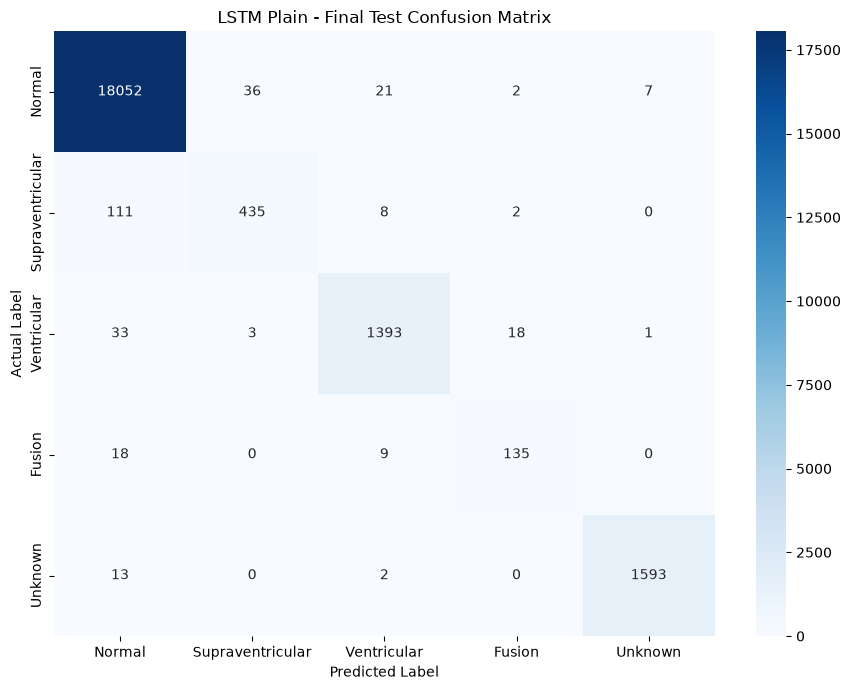

In [20]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("LSTM Plain - Final Test Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.tight_layout()

plt.savefig(
    FIGURES_PATH / "lstm_plain_final_test_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [21]:
cm_df = pd.DataFrame(
    cm,
    index=class_names,
    columns=class_names
)

cm_df.to_csv(
    METRICS_PATH / "lstm_plain_final_test_confusion_matrix.csv"
)

## 8. Limitations

Although the model achieved strong test performance, several limitations must be considered:

1. **Class imbalance:** Some heartbeat categories contain significantly fewer samples than others.
2. **Patient-level separation:** Patient identifiers are not available in the supplied dataset, so patient-independent evaluation cannot be established.
3. **Generalization:** Performance on this dataset does not guarantee equivalent performance on ECG recordings from other datasets, devices or populations.
4. **Clinical applicability:** This model is an educational machine learning project and is not validated for medical diagnosis or clinical use.

## 9. Conclusion

The final evaluation of the selected LSTM Plain model resulted in:

- 98.70% test accuracy.
- 94.70% macro precision.
- 91.30% macro recall.
- 92.89% Macro-F1.

The model demonstrated strong classification performance across most heartbeat categories, although Supraventricular and Fusion classifications remain areas for improvement.

The experimentation and final evaluation phases are now complete.

The next stage of the project focuses on converting the experimental implementation into a reusable application through code modularization, model inference and deployment.
